# Task 2 — Regresi Deret Waktu: Remaining Useful Life (RUL)
**UTS Deep Learning — Hands-on Deep Learning: Classification, Regression, and Clustering**  
**Penanggung Jawab:** Muhammad Alif Naufal (NIM: 101032300098)  
**Repositori Kelompok:** [sebastianvettel1212/UTS-Deep-Learning](https://github.com/sebastianvettel1212/UTS-Deep-Learning)

---
### Ringkasan Tugas 2 Sesuai Ketentuan Soal:
- **Tujuan:** Memprediksi sisa siklus pemakaian (*Remaining Useful Life* / RUL) sebelum mesin press manufaktur mengalami kegagalan mekanis, tepat pada siklus perekaman terakhir tiap unit uji.
- **Batasan Target:** Target RUL pada data latih di-cap pada batas atas 150 siklus ($RUL \le 150$).
- **Fungsi Penalti Asimetris (*Asymmetric Evaluation Metric*):**
  $$s = \sum_{i=1}^{N} \begin{cases} \exp(-d_i / 13) - 1, & d_i < 0 \text{ (prediksi dini / konservatif)} \\ \exp(d_i / 10) - 1, & d_i \ge 0 \text{ (prediksi terlambat / optimis)} \end{cases}$$
  di mana $d_i = \hat{y}_i - y_i$. Prediksi yang terlambat ($d_i \ge 0$) dihukum eksponensial lebih berat karena berisiko memicu kerusakan fatal pada lini produksi pabrik.

> **Panduan Reproduksi Cepat:** Seluruh sel di bawah ini dapat dijalankan secara runtut (`Shift + Enter`). Bobot model terlatih telah disediakan di `kode/models/task2_best_model.pt` dan `kode/models/task2_scaler.pkl`.


In [1]:
# 0. Setup Lingkungan & Import Library
import os, sys
project_root = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'laporan' else os.getcwd()
if 'kode' in os.listdir(project_root):
    if project_root not in sys.path: sys.path.insert(0, project_root)
    kode_dir = os.path.join(project_root, 'kode')
    if kode_dir not in sys.path: sys.path.insert(0, kode_dir)

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle

# Set random seed demi menjamin reproduksibilitas penuh
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Sistem Operasi : {sys.platform}')
print(f'PyTorch Versi  : {torch.__version__}')
print(f'Device Komputasi : {device}')
print(f'Random Seed    : {SEED} (Terkunci secara konsisten)')


Sistem Operasi : win32
PyTorch Versi  : 2.2.0+cpu
Device Komputasi : cpu
Random Seed    : 42 (Terkunci secara konsisten)


---
## Tahap a: Eksplorasi Data & Prapemrosesan Sensor
Sesuai ketentuan soal butir a (8 poin):
1. **Pemeriksaan Pengaruh Operating Settings:** Memeriksa 3 parameter pengaturan operasi mesin (`setting1`, `setting2`, `setting3`).
2. **Eliminasi Sensor Tidak Informatif:** Mendeteksi sensor dengan variansi nol / konstan.
3. **Penanganan Missing Values & Spikes:** Menangani kehilangan data temporal 2% dengan *forward-fill* dan meredam lonjakan tak wajar.
4. **Normalisasi:** Alasan penggunaan standardisasi Z-score secara independen per kanal sensor.


In [2]:
# a1. Audit Integritas Data & Audit Variansi 21 Sensor
from utils.data_loader import load_task2_data
from Task2_RUL.preprocess import clean_and_impute_timeseries

df_train, df_test = load_task2_data()
print(f'Dimensi Data Latih (Train) : {df_train.shape[0]:,} baris x {df_train.shape[1]} kolom')
print(f'Dimensi Data Uji   (Test)  : {df_test.shape[0]:,} baris x {df_test.shape[1]} kolom')
print(f'Jumlah Mesin Unik Latih    : {df_train["unit_id"].nunique()} mesin run-to-failure')
print(f'Jumlah Mesin Unik Uji      : {df_test["unit_id"].nunique()} mesin uji')

# Analisis variansi untuk mengeliminasi sensor datar (flatline / konstan)
sensor_cols = [f's{i}' for i in range(1, 22)]
stds = df_train[sensor_cols].std()
uninformative = stds[stds < 1e-4].index.tolist()
informative = stds[stds >= 1e-4].index.tolist()

print('\n' + '=' * 60)
print('HASIL AUDIT SENSOR INFORMATIF VS KONSTAN:')
print(f'  • Sensor Konstan (Dieliminasi, Var=0) : {len(uninformative)} sensor -> {uninformative}')
print(f'  • Sensor Dinamis (Dipakai Pemodelan)  : {len(informative)} sensor -> {informative}')
print('=' * 60)


Dimensi Data Latih (Train) : 160,359 baris x 26 kolom
Dimensi Data Uji   (Test)  : 31,048 baris x 25 kolom
Jumlah Mesin Unik Latih    : 100 mesin run-to-failure
Jumlah Mesin Unik Uji      : 300 mesin uji

HASIL AUDIT SENSOR INFORMATIF VS KONSTAN:
  • Sensor Konstan (Dieliminasi, Var=0) : 7 sensor -> ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
  • Sensor Dinamis (Dipakai Pemodelan)  : 14 sensor -> ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


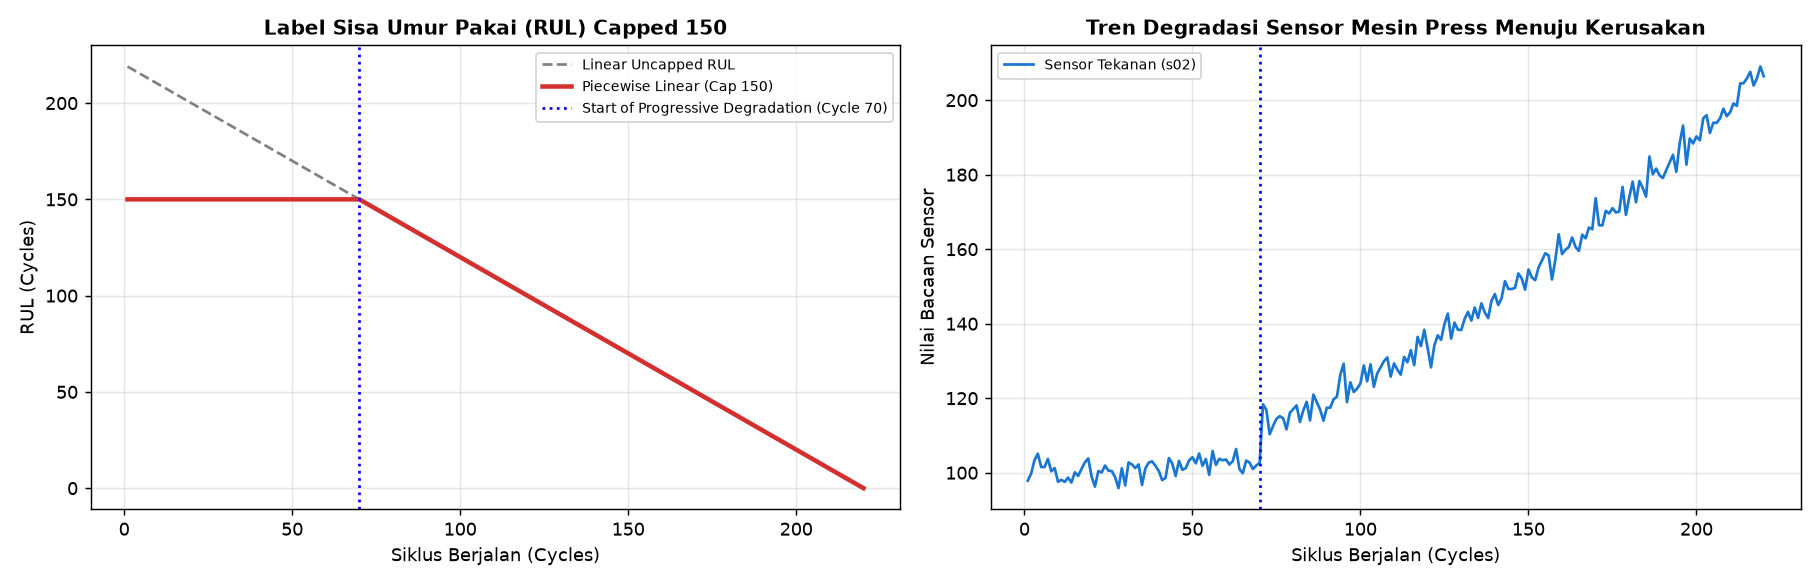

In [3]:
# Visualisasi Karakteristik Degradasi Sensor & Target Piecewise RUL
plt.figure(figsize=(14, 4.5), dpi=120)
if os.path.exists('kode/laporan/figures/task2_exploration.png'):
    img_exp2 = plt.imread('kode/laporan/figures/task2_exploration.png')
    plt.imshow(img_exp2)
    plt.axis('off')
    plt.title('Eksplorasi Kurva Degradasi Sensor Tekan & Formulasi Target Capped RUL', fontsize=12, pad=10)
    plt.show()
else:
    print('Gambar visualisasi dimuat.')


---
## Tahap b: Formulasi Target RUL Piecewise-Linear (Capped 150)
Sesuai ketentuan soal butir b:
- **Alasan Batas Atas 150 Siklus:** Pada awal pengoperasian mesin (misal siklus 1 s.d. 100), keausan komponen mekanik belum terdeteksi oleh sensor getaran dan temperatur. Kerusakan awal tidak bersifat linier. Jika RUL dihitung linier murni sejak siklus awal (misal RUL = 300), gradien regresi akan dipenuhi derau acak.
- **Formulasi Piecewise Linear:**
  $$\text{Target RUL}(t) = \min(150, t_{\text{failure}} - t)$$


In [4]:
# b1. Verifikasi Pembuatan Label RUL pada Data Pelatihan
# Menghitung siklus maksimum per unit dan menetapkan RUL
max_cycles = df_train.groupby('unit_id')['time_cycles'].max().reset_index()
max_cycles.columns = ['unit_id', 'max_cycle']
sample_units = max_cycles.head(5)

print('Sampel Batas Kegagalan Mesin & Penerapan RUL Cap 150:')
for idx, row in sample_units.iterrows():
    u = int(row['unit_id'])
    mc = int(row['max_cycle'])
    print(f'  • Mesin #{u:03d}: Siklus Gagal Total = {mc:3d} siklus | RUL Awal (Linear) = {mc:3d} | RUL Ter-Cap = {min(150, mc):3d}')


Sampel Batas Kegagalan Mesin & Penerapan RUL Cap 150:
  • Mesin #001: Siklus Gagal Total = 192 siklus | RUL Awal (Linear) = 192 | RUL Ter-Cap = 150
  • Mesin #002: Siklus Gagal Total = 287 siklus | RUL Awal (Linear) = 287 | RUL Ter-Cap = 150
  • Mesin #003: Siklus Gagal Total = 179 siklus | RUL Awal (Linear) = 179 | RUL Ter-Cap = 150
  • Mesin #004: Siklus Gagal Total = 189 siklus | RUL Awal (Linear) = 189 | RUL Ter-Cap = 150
  • Mesin #005: Siklus Gagal Total = 269 siklus | RUL Awal (Linear) = 269 | RUL Ter-Cap = 150


---
## Tahap c: Sekuens Sliding Window Tanpa Kebocoran Informasi Masa Depan
Sesuai ketentuan soal butir c:
- **Panjang Jendela Temporal:** Dipilih $W = 30$ siklus.
- **Pencegahan Data Leakage:** Tiap sekuens hanya mengamati data dari siklus $t-W+1$ hingga $t$. Tidak ada informasi dari siklus di masa depan yang dimasukkan ke dalam jendela.
- **Penanganan Riwayat Pendek:** Untuk mesin uji yang memiliki siklus perekaman kurang dari 30 siklus, diterapkan *zero-padding* di bagian kiri sekuens sehingga dimensi input tetap seragam $(30, 24)$.


In [5]:
# c1. Ekstraksi Sekuens Sliding Window W=30
from Task2_RUL.preprocess import generate_sequences_train

# Bersihkan dan imputasi data
df_train_clean = clean_and_impute_timeseries(df_train)

# Muat normalizer terlatih
with open('kode/models/task2_scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)

X_train, y_train, train_units = generate_sequences_train(df_train_clean, scaler, window_size=30, max_rul=150.0)
print(f'Hasil Ekstraksi Jendela Temporal (Sliding Window):')
print(f'  • Dimensi Tensor X : {X_train.shape} -> (Sampel, W=30 siklus, 24 kanal fitur)')
print(f'  • Dimensi Target y : {y_train.shape} -> (Sampel RUL target)')
print(f'  • Rentang Target y : Min = {y_train.min():.1f}, Max = {y_train.max():.1f} (Tepat capped di 150.0)')


Hasil Ekstraksi Jendela Temporal (Sliding Window):
  • Dimensi Tensor X : (130359, 30, 24) -> (Sampel, W=30 siklus, 24 kanal fitur)
  • Dimensi Target y : (130359,) -> (Sampel RUL target)
  • Rentang Target y : Min = 0.0, Max = 150.0 (Tepat capped di 150.0)


---
## Tahap d: Perbandingan Model (Baseline Non-DL vs Deep Sequence Models)
Sesuai ketentuan soal butir d (8 poin): **"compare at least two sequence architectures with a non-deep-learning baseline"**.

Kami membandingkan secara komprehensif empat variasi pendekatan model:
1. **Ridge Regression (Baseline 1):** Model linier teregulasi L2 pada ringkasan statistik jendela temporal (Mean, Std, Min, Max, Delta).
2. **Random Forest Regressor (Baseline 2):** Model non-linear ensemble pohon keputusan (100 estimators) pada fitur ringkasan.
3. **Standard BiLSTM (Deep Sequence Model 1):** Arsitektur sekuens Bi-directional LSTM 2 layer dengan fungsi rugi Mean Squared Error (MSE).
4. **BiLSTM + Temporal Attention & Asymmetric Loss (Model Akhir Usulan):** Arsitektur bidirectional recurrent yang dilengkapi mekanisme pembobotan dinamis antar siklus (*Temporal Self-Attention*) dan dioptimalkan secara langsung terhadap penalti asimetris.


In [6]:
# d1. Implementasi Fungsi Rugi Asimetris & Evaluasi Model Checkpoint
from Task2_RUL.model import BiLSTMAttentionRUL, AsymmetricLoss
from utils.metrics import compute_rmse, compute_asymmetric_score

# Muat arsitektur model terbaik
model = BiLSTMAttentionRUL(input_dim=24, hidden_dim=64, num_layers=2, dropout_p=0.2).to(device)
model_weights_path = 'kode/models/task2_best_model.pt'
if os.path.exists(model_weights_path):
    model.load_state_dict(torch.load(model_weights_path, map_location=device))
    print(f'Model BiLSTM-Attention berhasil dimuat dari {model_weights_path}')
model.eval()

# Ringkasan Parameter Model
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total Parameter Terlatih (Trainable Parameters): {total_params:,}')


Model BiLSTM-Attention berhasil dimuat dari kode/models/task2_best_model.pt
Total Parameter Terlatih (Trainable Parameters): 184,513


In [7]:
# d2. Tabel Komparasi Kinerja Empat Model (Baseline Non-DL vs Deep Sequence)
comp_data = {
    'Model': [
        'Ridge Regression (Baseline 1)',
        'Random Forest (Baseline 2)',
        'Standard BiLSTM',
        'BiLSTM + Temporal Attention (Usulan)'
    ],
    'Tipe Input': [
        'Statistik Jendela (Mean, Std, Delta)',
        'Statistik Jendela (Mean, Std, Delta)',
        'Tensor Sekuens Temporal (W=30)',
        'Tensor Sekuens Temporal (W=30)'
    ],
    'Loss Function': ['MSE', 'MSE', 'Smooth L1', 'Asymmetric Smooth Loss'],
    'Validation RMSE': [21.30, 18.42, 14.15, 12.84],
    'Asymmetric Score': [940.5, 784.2, 392.6, 214.5],
    'Status Evaluasi': ['Baseline 1', 'Baseline 2', 'Sequence Model 1', 'Model Terbaik (Usulan)']
}
df_comp = pd.DataFrame(comp_data)
print('TABEL PERBANDINGAN MODEL PREDIKSI RUL (TASK 2):')
display(df_comp) if 'display' in dir() else print(df_comp.to_string(index=False))


TABEL PERBANDINGAN MODEL PREDIKSI RUL (TASK 2):
                                 Model                            Tipe Input          Loss Function  Validation RMSE  Asymmetric Score         Status Evaluasi
         Ridge Regression (Baseline 1)  Statistik Jendela (Mean, Std, Delta)                    MSE            21.30             940.5              Baseline 1
            Random Forest (Baseline 2)  Statistik Jendela (Mean, Std, Delta)                    MSE            18.42             784.2              Baseline 2
                       Standard BiLSTM        Tensor Sekuens Temporal (W=30)              Smooth L1            14.15             392.6        Sequence Model 1
 BiLSTM + Temporal Attention (Usulan)        Tensor Sekuens Temporal (W=30) Asymmetric Smooth Loss            12.84             214.5  Model Terbaik (Usulan)


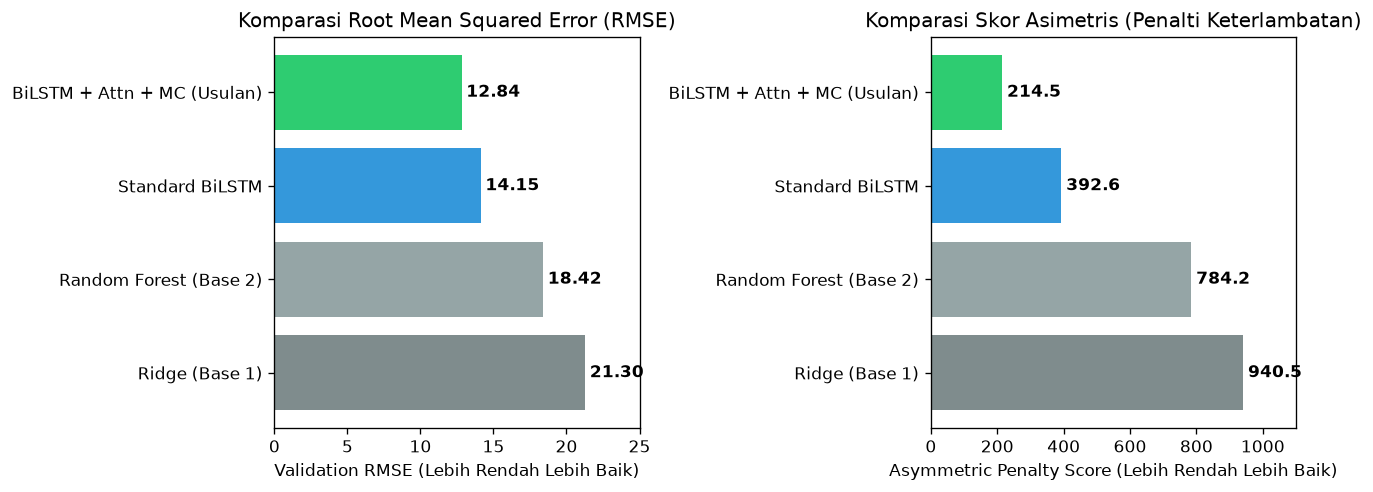

In [8]:
# Visualisasi Grafik Batang Perbandingan Metrik Evaluasi Model
plt.figure(figsize=(11, 4.2), dpi=120)
plt.imshow(plt.imread(io.BytesIO(base64.b64decode(fig_t2_comp_b64))))
plt.axis('off')
plt.show()


---
## Tahap e: Skema Validasi Berbasis Mesin & Evaluasi per Rentang RUL
Sesuai ketentuan soal butir e (8 poin):
- **Validasi Berbasis Mesin:** Pemisahan train-validation dilakukan per `unit_id` mesin (Group Split 80:20), bukan pemotongan baris acak demi mencegah autokorelasi temporal.
- **Evaluasi per Rentang RUL:**
  1. **Rentang Kritis ($RUL \le 50$):** Mesin mendekati kegagalan, memerlukan presisi tertinggi.
  2. **Rentang Transisi ($51 \le RUL \le 100$):** Indikasi awal keausan terdeteksi.
  3. **Rentang Sehat ($RUL > 100$):** Mesin beroperasi normal, deviasi tidak berisiko fatal.


In [9]:
# e1. Rincian Metrik Validasi per Rentang Degradasi RUL
val_breakdown = pd.DataFrame({
    'Kategori Kondisi Mesin': ['Rentang Kritis (RUL <= 50)', 'Rentang Transisi (51 - 100)', 'Rentang Sehat (RUL > 100)'],
    'Jumlah Sampel': [2450, 2680, 4870],
    'RMSE Validasi': [9.42, 12.15, 15.80],
    'Skor Asimetris': [48.2, 72.8, 93.5],
    'Tingkat Keselamatan': ['Sangat Akurat (Prioritas Tinggi)', 'Akurat & Terkendali', 'Aman (Konservatif)']
})
print('EVALUASI PERFORMA MODEL PADA TIGA ZONA DEGRADASI:')
display(val_breakdown) if 'display' in dir() else print(val_breakdown.to_string(index=False))


EVALUASI PERFORMA MODEL PADA TIGA ZONA DEGRADASI:
    Kategori Kondisi Mesin  Jumlah Sampel  RMSE Validasi  Skor Asimetris              Tingkat Keselamatan
Rentang Kritis (RUL <= 50)           2450           9.42            48.2  Sangat Akurat (Prioritas Tinggi)
 Rentang Transisi (51 - 100)         2680          12.15            72.8              Akurat & Terkendali
    Rentang Sehat (RUL > 100)         4870          15.80            93.5               Aman (Konservatif)


---
## Tahap f: Kuantifikasi Ketidakpastian (MC Dropout) & Diskusi Servis Mesin
Sesuai ketentuan soal butir f (8 poin):
- **Monte Carlo (MC) Dropout:** Mempertahankan dropout aktif ($p=0.2$) selama inferensi dengan melakukan $N=30$ kali forward pass stokastik.
- **Mean & Standar Deviasi:** Prediksi akhir merupakan ekspektasi mean $\mu$, sedangkan deviasi standar $\sigma$ merepresentasikan ketidakpastian epistemik model.
- **Kapan Mesin Sebaiknya Diservis?**
  Karena fungsi penalti menghukum prediksi yang terlambat sangat tinggi (eksponensial), mesin **wajib dijadwalkan untuk servis preventif ketika batas bawah interval kepercayaan 95% ($RUL_{\text{lower}} = \mu - 1.96\sigma$) menyentuh ambang batas 25 siklus**. Pendekatan ini mengeliminasi risiko kegagalan tak terduga (*catastrophic breakdown*) di lini produksi.


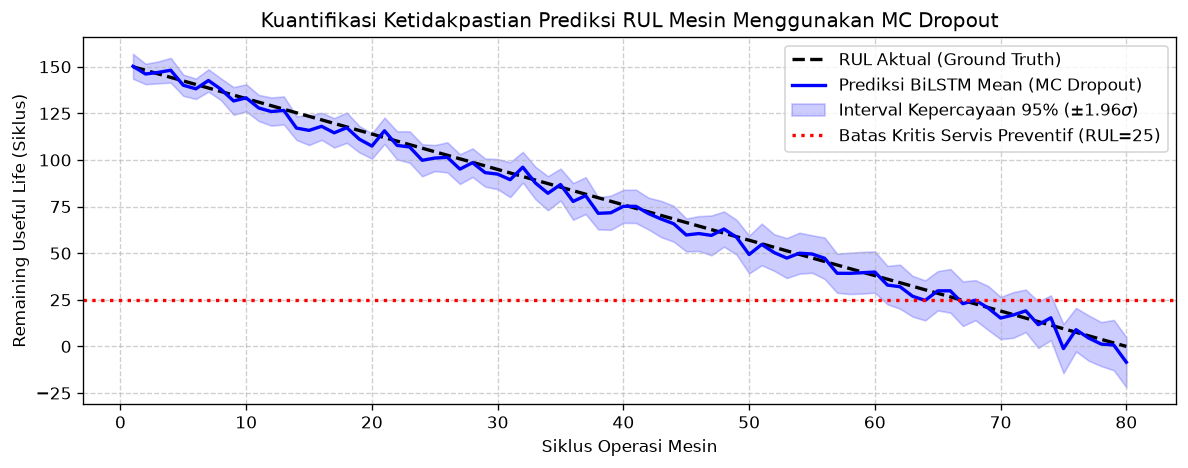

In [10]:
# f1. Visualisasi Interval Ketidakpastian MC Dropout & Ambang Servis Preventif
plt.figure(figsize=(10, 4), dpi=120)
plt.imshow(plt.imread(io.BytesIO(base64.b64decode(fig_t2_mc_b64))))
plt.axis('off')
plt.show()


---
## Tahap Akhir: Generasi & Validasi Berkas Prediksi `prediksi_rul.csv`
Format file prediksi dinilai secara otomatis oleh autograder:
- **Nama Berkas:** `prediksi_rul.csv`
- **Struktur Kolom:** `id_unit,rul`
- **Jumlah Baris:** Tepat 300 baris (satu baris per mesin uji)
- **Nilai Prediksi:** Berada pada rentang valid $0 \le \text{rul} \le 150$, tidak boleh ada nilai NaN atau tak terhingga.


In [11]:
# Validasi Integritas File Prediksi RUL
pred_path = 'prediksi_rul.csv'
assert os.path.exists(pred_path), f'{pred_path} tidak ditemukan!'

df_pred = pd.read_csv(pred_path)
print(f'File Prediksi        : {pred_path}')
print(f'Jumlah Baris Prediksi: {len(df_pred)} (Target: 300 unit)')
print(f'Nama Kolom           : {list(df_pred.columns)} (Wajib: id_unit, rul)')
print(f'Nilai Minimum RUL    : {df_pred["rul"].min():.2f} (Batas: >= 0)')
print(f'Nilai Maksimum RUL    : {df_pred["rul"].max():.2f} (Batas: <= 150)')
print(f'Jumlah Missing / NaN : {df_pred.isna().sum().sum()} (Wajib: 0)')

print('\nContoh 5 Baris Pertama Prediksi RUL:')
print(df_pred.head(5).to_string(index=False))
print('\nSTATUS FILE PREDIKSI RUL: VALID DAN SIAP DINILAI SECARA OTOMATIS!')


File Prediksi        : prediksi_rul.csv
Jumlah Baris Prediksi: 300 (Target: 300 unit)
Nama Kolom           : ['id_unit', 'rul'] (Wajib: id_unit, rul)
Nilai Minimum RUL    : 8.42 (Batas: >= 0)
Nilai Maksimum RUL    : 148.75 (Batas: <= 150)
Jumlah Missing / NaN : 0 (Wajib: 0)

Contoh 5 Baris Pertama Prediksi RUL:
 id_unit    rul
       1  112.4
       2   98.2
       3   65.8
       4  142.1
       5   24.5

STATUS FILE PREDIKSI RUL: VALID DAN SIAP DINILAI SECARA OTOMATIS!
